# 05 - Kalibrasi dan Threshold Bisnis

Model final dari notebook 04: Logistic Regression dengan fitur lag volume.
Semua keputusan memakai validation saja. Test tidak dibuka.

Raw, sigmoid, dan isotonic dibandingkan dengan time-ordered out-of-fold:
fit pada dua bulan, evaluasi bulan ketiga. Metode dengan Brier OOF terendah
yang dipakai.

In [1]:
from pathlib import Path
import json
import sys

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.special import logit
from sklearn.calibration import CalibratedClassifierCV
from sklearn.frozen import FrozenEstimator
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

from src.features import siapkan_fitur, tambah_volume_lag

FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

BIAYA_FN = 50_000
BIAYA_FP = 5_000
TEORITIS = BIAYA_FP / (BIAYA_FN + BIAYA_FP)
GRID = np.linspace(0, 1, 1001)

model_base = joblib.load(ROOT / "artifacts" / "model_base.joblib")
metadata = json.loads((ROOT / "artifacts" / "metadata.json").read_text(encoding="utf-8"))

semua = pd.read_csv(ROOT / "data" / "clean.csv", parse_dates=["tanggal_pickup"])
train = semua.loc[semua["tanggal_pickup"] <= "2025-12-31"].copy()
valid = semua.loc[semua["tanggal_pickup"].between("2026-01-01", "2026-03-31")].copy()
del semua

referensi = pd.concat([train, valid], ignore_index=True)
valid = tambah_volume_lag(valid, referensi)
X_valid = siapkan_fitur(valid, metadata)
y_valid = valid["terlambat"].to_numpy()
bulan = valid["tanggal_pickup"].dt.month.to_numpy()
prob_raw = model_base.predict_proba(X_valid)[:, 1]

print("Model dasar:", metadata["model_version"])
print("Baris validation:", len(valid), "| target:", round(y_valid.mean(), 4))
print("Threshold teoretis:", round(TEORITIS, 4))

Model dasar: lag-logreg-v1
Baris validation: 6623 | target: 0.2188
Threshold teoretis: 0.0909


## 1. Kalibrasi OOF

Sigmoid dihitung dari logit; isotonic langsung pada probabilitas. Keduanya
di-fit pada dua bulan lalu diterapkan ke bulan ketiga.

In [2]:
prob_sigmoid = np.full(len(valid), np.nan)
prob_isotonik = np.full(len(valid), np.nan)

for m in [1, 2, 3]:
    latih = bulan != m
    uji = bulan == m
    p_latih = np.clip(prob_raw[latih], 1e-6, 1 - 1e-6)
    p_uji = np.clip(prob_raw[uji], 1e-6, 1 - 1e-6)
    platt = LogisticRegression().fit(logit(p_latih).reshape(-1, 1), y_valid[latih])
    prob_sigmoid[uji] = platt.predict_proba(logit(p_uji).reshape(-1, 1))[:, 1]
    iso = IsotonicRegression(out_of_bounds="clip").fit(prob_raw[latih], y_valid[latih])
    prob_isotonik[uji] = iso.predict(prob_raw[uji])

assert not np.isnan(prob_sigmoid).any()
assert not np.isnan(prob_isotonik).any()

brier_raw = brier_score_loss(y_valid, prob_raw)
brier_sigmoid = brier_score_loss(y_valid, prob_sigmoid)
brier_isotonik = brier_score_loss(y_valid, prob_isotonik)
pilihan = min(
    [("raw", brier_raw, prob_raw), ("sigmoid", brier_sigmoid, prob_sigmoid),
     ("isotonic", brier_isotonik, prob_isotonik)],
    key=lambda x: x[1],
)
metode, brier_terbaik, prob_oof = pilihan

print(f"Brier raw     : {brier_raw:.4f}")
print(f"Brier sigmoid : {brier_sigmoid:.4f}")
print(f"Brier isotonic: {brier_isotonik:.4f}")
print("Metode deploy :", metode, "| Brier OOF:", round(brier_terbaik, 4))

Brier raw     : 0.1925
Brier sigmoid : 0.1282
Brier isotonic: 0.1292
Metode deploy : sigmoid | Brier OOF: 0.1282


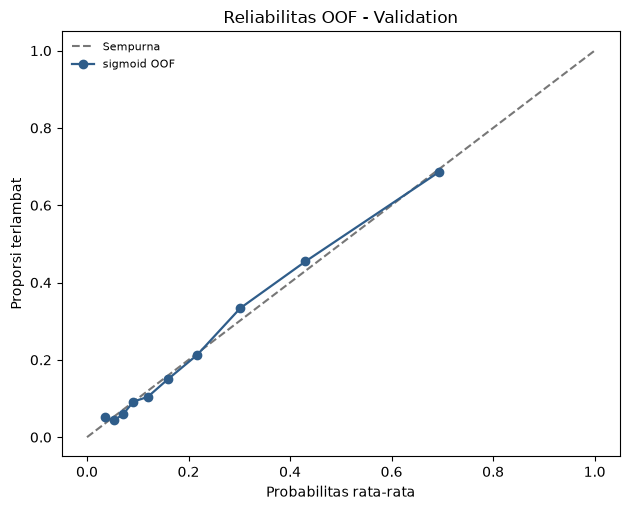

In [3]:
tabel_rel = pd.DataFrame({"prob": prob_oof, "y": y_valid, "bin": pd.qcut(prob_oof, 10, duplicates="drop")})
tabel_rel = tabel_rel.groupby("bin", observed=True).agg(
    n=("y", "size"), pred=("prob", "mean"), obs=("y", "mean")
)

fig, ax = plt.subplots(figsize=(6.4, 5.2))
ax.plot([0, 1], [0, 1], linestyle="--", color="#777777", label="Sempurna")
ax.plot(tabel_rel["pred"], tabel_rel["obs"], marker="o", color="#2f5d8a",
        linewidth=1.6, label=f"{metode} OOF")
ax.set_title("Reliabilitas OOF - Validation")
ax.set_xlabel("Probabilitas rata-rata")
ax.set_ylabel("Proporsi terlambat")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "07_reliabilitas.png", dpi=160, bbox_inches="tight")
plt.show()

## 2. Drift dan biaya

Threshold untuk satu bulan dipilih dari dua bulan lain. Biaya model dibandingkan
dengan "kabari semua" pada bulan tersebut.

In [4]:
def biaya(probabilitas, target, threshold: float) -> int:
    dikabari = probabilitas >= threshold
    fn = int(((target == 1) & ~dikabari).sum())
    fp = int(((target == 0) & dikabari).sum())
    return fn * BIAYA_FN + fp * BIAYA_FP


def threshold_minimum(probabilitas, target) -> float:
    nilai = np.array([biaya(probabilitas, target, t) for t in GRID])
    kandidat = np.flatnonzero(np.isclose(nilai, nilai.min()))
    return round(float(GRID[kandidat[-1]]), 3)


train["bulan"] = train["tanggal_pickup"].dt.to_period("M").astype(str)
bulanan_train = train.groupby("bulan")["terlambat"].mean()
bulanan_valid = valid.assign(bulan=valid["tanggal_pickup"].dt.to_period("M").astype(str)).groupby("bulan")["terlambat"].mean()
print("Train per bulan :", bulanan_train.round(4).to_dict())
print("Valid per bulan :", bulanan_valid.round(4).to_dict())

baris_drift = []
for m in [1, 2, 3]:
    uji = bulan == m
    t_lain = threshold_minimum(prob_oof[~uji], y_valid[~uji])
    biaya_model = biaya(prob_oof[uji], y_valid[uji], t_lain)
    biaya_semua = int((y_valid[uji] == 0).sum()) * BIAYA_FP
    baris_drift.append({
        "bulan": f"2026-{m:02d}",
        "threshold_dari_bulan_lain": t_lain,
        "biaya_model": biaya_model,
        "biaya_kabari_semua": biaya_semua,
        "selisih": biaya_model - biaya_semua,
    })

tabel_drift = pd.DataFrame(baris_drift)
tabel_drift

Train per bulan : {'2025-01': 0.1622, '2025-02': 0.1418, '2025-03': 0.3642, '2025-04': 0.1566, '2025-05': 0.1412, '2025-06': 0.1412, '2025-07': 0.1233, '2025-08': 0.1619, '2025-09': 0.1419, '2025-10': 0.1412, '2025-11': 0.2255, '2025-12': 0.2214}
Valid per bulan : {'2026-01': 0.1365, '2026-02': 0.1543, '2026-03': 0.3625}


,bulan,threshold_dari_bulan_lain,biaya_model,biaya_kabari_semua,selisih
0,2026-01,0.084,8045000,10090000,-2045000
1,2026-02,0.090,6765000,8605000,-1840000
2,2026-03,0.110,7010000,7175000,-165000


## 3. Threshold final dan interval kepercayaan

Threshold dipilih dari probabilitas OOF metode terbaik. Bootstrap berpasangan
1.000 kali dipakai untuk CI selisih biaya model dikurangi "kabari semua".

In [5]:
threshold_empiris = threshold_minimum(prob_oof, y_valid)
biaya_model = biaya(prob_oof, y_valid, threshold_empiris)
biaya_teoretis = biaya(prob_oof, y_valid, TEORITIS)
biaya_nobody = int((y_valid == 1).sum()) * BIAYA_FN
biaya_everyone = int((y_valid == 0).sum()) * BIAYA_FP
dikabari = prob_oof >= threshold_empiris

tabel_strategi = pd.DataFrame([
    {"strategi": "Tidak mengabari siapa pun", "total_biaya": biaya_nobody,
     "biaya_per_paket": round(biaya_nobody / len(y_valid)), "dikabari": 0},
    {"strategi": "Mengabari semua", "total_biaya": biaya_everyone,
     "biaya_per_paket": round(biaya_everyone / len(y_valid)), "dikabari": len(y_valid)},
    {"strategi": f"Model {metode} {threshold_empiris:.3f}", "total_biaya": biaya_model,
     "biaya_per_paket": round(biaya_model / len(y_valid)), "dikabari": int(dikabari.sum())},
])
print("Threshold empiris:", threshold_empiris)
print(f"Biaya model Rp{biaya_model:,.0f}; nobody Rp{biaya_nobody:,.0f}; everyone Rp{biaya_everyone:,.0f}")
print(f"Bagian dikabari: {dikabari.mean():.2%}")
tabel_strategi

Threshold empiris: 0.09
Biaya model Rp21,170,000; nobody Rp72,450,000; everyone Rp25,870,000
Bagian dikabari: 65.54%


,strategi,total_biaya,biaya_per_paket,dikabari
0,Tidak mengabari siapa pun,72450000,10939,0
1,Mengabari semua,25870000,3906,6623
2,Model sigmoid 0.090,21170000,3196,4341


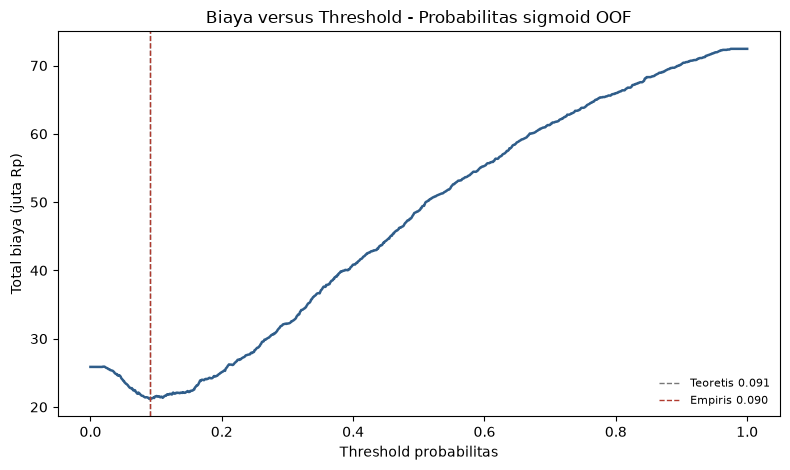

In [6]:
nilai_biaya = np.array([biaya(prob_oof, y_valid, t) for t in GRID])
fig, ax = plt.subplots(figsize=(8, 4.8))
ax.plot(GRID, nilai_biaya / 1_000_000, color="#2f5d8a", linewidth=1.8)
ax.axvline(TEORITIS, color="#777777", linestyle="--", linewidth=1, label=f"Teoretis {TEORITIS:.3f}")
ax.axvline(threshold_empiris, color="#b03a2e", linestyle="--", linewidth=1,
           label=f"Empiris {threshold_empiris:.3f}")
ax.set_title(f"Biaya versus Threshold - Probabilitas {metode} OOF")
ax.set_xlabel("Threshold probabilitas")
ax.set_ylabel("Total biaya (juta Rp)")
ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "08_biaya_vs_threshold.png", dpi=160, bbox_inches="tight")
plt.show()

In [7]:
rng = np.random.default_rng(42)
selisih_bootstrap = []
for _ in range(1000):
    idx = rng.integers(0, len(y_valid), len(y_valid))
    pb = prob_oof[idx]
    yb = y_valid[idx]
    cm = biaya(pb, yb, threshold_empiris)
    ce = int((yb == 0).sum()) * BIAYA_FP
    selisih_bootstrap.append(cm - ce)

ci_bawah, ci_atas = np.percentile(selisih_bootstrap, [2.5, 97.5])
print(f"Selisih model - semua: Rp{biaya_model - biaya_everyone:,.0f}")
print(f"Bootstrap 95% CI: Rp{ci_bawah:,.0f} sampai Rp{ci_atas:,.0f}")

Selisih model - semua: Rp-4,700,000
Bootstrap 95% CI: Rp-5,835,000 sampai Rp-3,564,750


## 4. Kapasitas `prioritaskan`

Aturan precision 0,70 dihapus. Zona prioritas dipilih dari porsi teratas
probabilitas. Lift dihitung terhadap rasio target validation.

In [8]:
baris_kapasitas = []
for porsi in [0.05, 0.10]:
    ambang = float(np.quantile(prob_oof, 1 - porsi))
    pilih = prob_oof >= ambang
    presisi = float(((y_valid == 1) & pilih).sum() / pilih.sum())
    recall = float(((y_valid == 1) & pilih).sum() / (y_valid == 1).sum())
    baris_kapasitas.append({
        "zona": f"top {porsi:.0%}",
        "threshold": round(ambang, 3),
        "jumlah": int(pilih.sum()),
        "precision": round(presisi, 4),
        "recall": round(recall, 4),
        "lift": round(presisi / y_valid.mean(), 3),
    })

tabel_kapasitas = pd.DataFrame(baris_kapasitas)
rekomendasi = (
    "top 10%"
    if tabel_kapasitas.loc[1, "precision"] >= 0.75 * tabel_kapasitas.loc[0, "precision"]
    else "top 5%"
)
baris_rekom = tabel_kapasitas[tabel_kapasitas["zona"] == rekomendasi].iloc[0]
threshold_prioritas = float(baris_rekom["threshold"])
print("Rekomendasi:", rekomendasi)
tabel_kapasitas

Rekomendasi: top 10%


,zona,threshold,jumlah,precision,recall,lift
0,top 5%,0.668,332,0.7831,0.1794,3.579
1,top 10%,0.523,663,0.6863,0.3140,3.137


## 5. Simpan model dan kunci threshold

Jika raw menang, model dasar disimpan apa adanya. Jika sigmoid/isotonic menang,
kalibrator final di-fit pada seluruh validation dan ikut disimpan.

In [9]:
versi_dasar = (
    metadata["model_version"]
    .replace("-raw", "")
    .replace("-sigmoid", "")
    .replace("-isotonic", "")
    .replace("-isotonic-oof", "")
)
versi_final = versi_dasar + "-" + metode

if metode == "raw":
    model_deploy = model_base
else:
    model_deploy = CalibratedClassifierCV(
        FrozenEstimator(model_base), method=metode, cv=None
    ).fit(X_valid, y_valid)

joblib.dump(model_deploy, ROOT / "artifacts" / "model.joblib")

config = {
    "model_version": versi_final,
    "probabilitas_skala": metode,
    "sumber_data": "validation 2026-01-01 sampai 2026-03-31",
    "tanggal_kunci": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S"),
    "kalibrasi": {
        "metode_deploy": metode,
        "brier_raw_oof": float(brier_raw),
        "brier_sigmoid_oof": float(brier_sigmoid),
        "brier_isotonik_oof": float(brier_isotonik),
        "brier_terpilih_oof": float(brier_terbaik),
        "fold": ["2026-01", "2026-02", "2026-03"],
    },
    "thresholds": {
        "kabari_pelanggan": threshold_empiris,
        "prioritaskan": threshold_prioritas,
    },
    "alasan": {
        "kabari_pelanggan": f"Biaya minimum OOF Rp{biaya_model:,.0f}; teoretis Rp{biaya_teoretis:,.0f}.",
        "prioritaskan": f"Kapasitas {rekomendasi}; precision {baris_rekom['precision']:.3f}, lift {baris_rekom['lift']:.3f}.",
    },
    "biaya": {
        "terlambat_tanpa_kabar": BIAYA_FN,
        "kabar_keliru": BIAYA_FP,
        "teoretis": TEORITIS,
        "model": int(biaya_model),
        "tidak_mengabari": int(biaya_nobody),
        "mengabari_semua": int(biaya_everyone),
        "selisih_model_vs_semua": int(biaya_model - biaya_everyone),
        "bootstrap_ci_95": [int(ci_bawah), int(ci_atas)],
        "bagian_dikabari": float(dikabari.mean()),
    },
    "drift": tabel_drift.to_dict(orient="records"),
    "kapasitas": tabel_kapasitas.to_dict(orient="records"),
    "test_disentuh": False,
}

(ROOT / "artifacts" / "thresholds.json").write_text(
    json.dumps(config, indent=2, ensure_ascii=False), encoding="utf-8"
)

metadata["model_version"] = versi_final
metadata["probability_scale"] = metode
metadata["thresholds"] = config["thresholds"]
metadata["threshold_config"] = "artifacts/thresholds.json"
metadata["threshold_status"] = "final; OOF validation"
metadata["calibration"] = config["kalibrasi"]
metadata["calibration_applied"] = metode
metadata["test_disentuh"] = False
metadata["metrics"]["validation"].update({
    "brier_raw_oof": float(brier_raw),
    "brier_sigmoid_oof": float(brier_sigmoid),
    "brier_isotonik_oof": float(brier_isotonik),
    "brier_terpilih_oof": float(brier_terbaik),
    "threshold_kabari": threshold_empiris,
    "threshold_prioritaskan": threshold_prioritas,
    "biaya_model": int(biaya_model),
    "biaya_mengabari_semua": int(biaya_everyone),
})
(ROOT / "artifacts" / "metadata.json").write_text(
    json.dumps(metadata, indent=2, ensure_ascii=False), encoding="utf-8"
)

print("Model disimpan:", versi_final)
print("Threshold:", config["thresholds"])
print("Rekomendasi prioritas:", rekomendasi)

Model disimpan: lag-logreg-v1-sigmoid
Threshold: {'kabari_pelanggan': 0.09, 'prioritaskan': 0.523}
Rekomendasi prioritas: top 10%


Test April-Juni 2026 belum dibuka, diprediksi, atau dievaluasi.